# Implementing Quantum Oracle Sketching (QOS), step by step

This notebook builds Quantum Oracle Sketching from scratch: first as real gate-level circuits in PennyLane, then as a fast NumPy simulator that is checked against those circuits.

It accompanies the report *Quantum Oracle Sketching on Bank-Held Data* and the repository [`qos-rbc-experiments`](https://github.com/THAKKAR82/qos-rbc-experiments) (tag `v1-qos-findings`). Paper: Zhao et al., *Exponential quantum advantage in processing massive classical data*, arXiv:2604.07639.

| Part | What you build | Key idea |
|---|---|---|
| 1 | A phase oracle from a data stream, gate by gate | One data sample = one small gate |

Parts 2–4 (using the oracle, the matrix oracle and a toy classifier, and the costs at bank scale) are in the companion notebook [`08b_qos_technical_walkthrough.ipynb`](08b_qos_technical_walkthrough.ipynb).

**Presenting.** Each section opens with a one-line **In plain English** summary for non-technical listeners; the code and **Technical note** cells are for the technical audience.

Everything is a classical simulation on a laptop; nothing runs on quantum hardware. Runs in the project's main environment (`numpy`, `matplotlib`, `pennylane`) in under a minute.

In [1]:
import numpy as np                       # fast arrays and maths
import matplotlib.pyplot as plt          # charts
import pennylane as qml                  # quantum-circuit simulator

rng = np.random.default_rng(42)          # seeded randomness: same results every run

# One colour-blind-checked palette; at most three series per chart.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # the three data colours
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"     # text, labels, grid lines
# One clean, consistent style for every chart below
plt.rcParams.update({   # start of the chart style settings
    # sharpness, text size, axis colour
    "figure.dpi": 110, "font.size": 10.5, "axes.edgecolor": MUTED,
    # colours of labels and tick marks
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,   # hide the top and right box edges
    # light grid lines behind the data
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False,   # thicker lines; no box round the legend
})   # end of the style settings
print("PennyLane", qml.__version__)       # record which simulator version ran

PennyLane 0.45.1


## Part 1. Build a phase oracle from a data stream

**In plain English:** we want the quantum computer to "know" a list of 16 yes/no tags all at once. Instead of loading the list, we let examples stream past and turn each one into a tiny rotation.

### 1.1 The target

The oracle flips the sign of every "yes" item:

$$O_f\,|x\rangle = (-1)^{f(x)}\,|x\rangle = e^{i\pi f(x)}|x\rangle .$$

It is diagonal, so it is fully described by one phase per item. 16 items need $n=4$ qubits.

In [2]:
n = 4                                   # 4 qubits ...
N = 2 ** n                              # ... can label 2^4 = 16 transactions
# f: one yes/no tag per item -- think: a fraud flag per transaction
f = rng.integers(0, 2, size=N)          # hidden tags; the algorithm never sees this array
target_phase = np.pi * f                # goal: a half-turn (pi) for fraud, none otherwise
target_diag = np.exp(1j * target_phase) # the same goal as a sign: -1 fraud, +1 normal
print("f(x) =", f)                      # show the answer key (for checking only)

f(x) = [0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1]


### 1.2 The data stream

QOS only ever sees a stream of random examples $(x, f(x))$, one at a time, with $x$ drawn uniformly. Nothing is stored.

In [3]:
def data_stream(f, M, rng):   # examples arrive one at a time
    # Yield M examples (x, f(x)) with x uniform over items. A generator: nothing is kept.
    for x in rng.integers(0, len(f), size=M):   # pick M transactions at random
        yield int(x), int(f[x])                 # hand over (transaction, flag), forget it

print(list(data_stream(f, 8, np.random.default_rng(0))))   # peek at 8 stream examples

[(13, 1), (10, 1), (8, 0), (4, 0), (4, 0), (0, 0), (1, 1), (0, 0)]


### 1.3 One sample = one gate

For each sample $(x, f(x))$, apply a small phase $\theta f(x)$ to the basis state $|x\rangle$ only, with $\theta = \pi N / M$. On average item $x$ is visited $M/N$ times, so its phases add up to $\pi f(x)$.

At gate level, "phase on $|x\rangle$ only" is a multi-controlled phase gate: control on the first $n-1$ bits of $x$, phase the last qubit, with $X$ gates to handle a 0 in the last bit.

In [4]:
def qos_gate(x, fx, theta, n):   # one stream example -> one QOS gate
    # Apply phase theta*f(x) to basis state |x> only (wire 0 = most significant bit).
    bits = [int(b) for b in format(x, f"0{n}b")]   # transaction number as 4 bits
    # PauliX wrapping: the gate below fires on a 1 in the last bit,
    # so if x ends in 0 we flip that bit first, and flip it back after
    if bits[-1] == 0:   # does x end in a 0? then flip it
        qml.PauliX(n - 1)                          # flip the last bit (0 <-> 1)
    # Controlled PhaseShift: rotate only transaction x. It fires only when
    # the first 3 bits match x; fx = 0 means no rotation at all, so
    # each fraud example rotates its own transaction slightly (by theta)
    qml.ctrl(qml.PhaseShift(theta * fx, wires=n - 1),   # phase-nudge the last qubit by theta x f(x)
             # only if the first 3 bits match x
             control=list(range(n - 1)), control_values=bits[:-1])
    if bits[-1] == 0:   # if we flipped the last bit before ...
        qml.PauliX(n - 1)                          # undo the flip; others untouched

dev = qml.device("default.qubit", wires=n)         # a simulated 4-qubit computer

@qml.qnode(dev)                                    # make the function a circuit
def sketched_state(samples, theta):   # circuit: examples in, quantum state out
    # Hadamard on every qubit: put all 16 transactions in superposition
    for w in range(n):   # for each of the 4 qubits ...
        qml.Hadamard(w)                  # uniform superposition over all items
    for x, fx in samples:                # stream: one gate per sample, then discard it
        qos_gate(x, fx, theta, n)   # add this example's gate, then move on
    return qml.state()                   # read out the full simulated state

demo_samples = list(data_stream(f, 3, np.random.default_rng(1)))   # 3 examples
print("First three samples:", demo_samples)   # show them as (transaction, flag)
# Draw the circuit those 3 examples build (nudge size as if M = 300)
print(qml.draw(sketched_state)(demo_samples, np.pi * N / 300))

First three samples: [(7, 1), (8, 0), (12, 1)]
0: ──H─╭○───────────╭●──────────────╭●───────────┤  State
1: ──H─├●───────────├○──────────────├●───────────┤  State
2: ──H─├●───────────├○──────────────├○───────────┤  State
3: ──H─╰Rϕ(0.17)──X─╰Rϕ(0.00)──X──X─╰Rϕ(0.17)──X─┤  State


### 1.4 Run the circuit, and check a fast simulator against it

Gate-level simulation is slow for large $M$. Because every QOS gate is diagonal, the whole sketch is just "add $\theta f(x)$ to item $x$'s phase", which NumPy can do instantly. We verify the two agree, then use NumPy for big streams.

**Technical note:** the phase vector below exists only in the *simulation*. On hardware, each sample is applied as a gate and discarded; the only "memory" is the quantum state.

In [5]:
def sketch_phases(samples, theta, N):   # the same sketch, without a circuit
    # Fast simulator: accumulate each sample's phase onto its item.
    phases = np.zeros(N)                 # every transaction starts unrotated
    for x, fx in samples:   # go through the stream once
        phases[x] += theta * fx          # each fraud example adds one small nudge
    return phases   # one total rotation per transaction

M = 400                                  # stream length: 400 examples
theta = np.pi * N / M                    # nudge size: ~25 visits x nudge = pi
samples = list(data_stream(f, M, np.random.default_rng(1)))   # draw the stream

state = sketched_state(samples, theta)                 # PennyLane, 400 gates
circuit_diag = state * np.sqrt(N)                      # amplitudes = e^{i phase_x} / sqrt(N)
numpy_diag = np.exp(1j * sketch_phases(samples, theta, N))   # same, via NumPy

# The circuit and the shortcut should agree to rounding error
print(f"PennyLane vs NumPy, max difference: {np.max(np.abs(circuit_diag - numpy_diag)):.1e}")

def fast_sketch_phases(f, M, rng):   # fast version for very long streams
    # Vectorised version for large M: same random draws, counts visits per item.
    # count how many times each transaction was drawn
    counts = np.bincount(rng.integers(0, len(f), size=M), minlength=len(f))
    return np.pi * len(f) / M * f * counts   # visits x nudge, fraud only

# Check the fast version gives exactly the same phases
same = np.allclose(fast_sketch_phases(f, M, np.random.default_rng(1)), sketch_phases(samples, theta, N))
print("Vectorised sketch identical to sample-by-sample sketch:", same)   # True means identical
# How far 400 examples still leave us from the exact oracle
print(f"Sketch vs exact oracle after {M} samples, worst item: "
      f"{np.max(np.abs(numpy_diag - target_diag)):.2f}")   # largest gap over all 16 transactions

PennyLane vs NumPy, max difference: 2.7e-15
Vectorised sketch identical to sample-by-sample sketch: True
Sketch vs exact oracle after 400 samples, worst item: 1.27


### 1.5 Why small nudges, not big flips

**In plain English:** the naive store-nothing approach (flip the sign every time an item appears) fails, because an item seen twice gets flipped back. Small nudges simply add up.

Orange arrows are the targets; blue arrows are what the stream built (first 8 items shown).

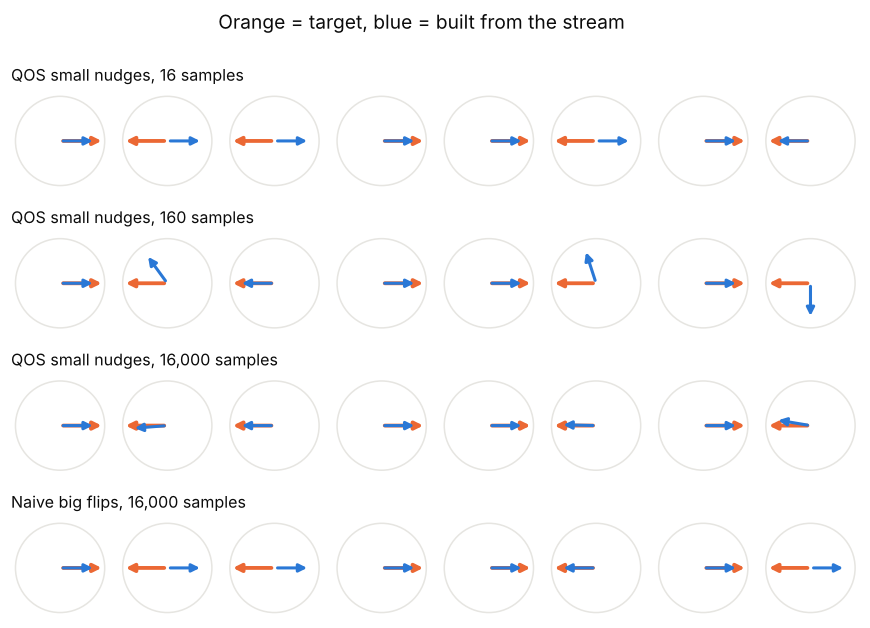

In [6]:
def big_flip_phases(samples, N):   # the naive alternative, for comparison
    # Naive: flip on every visit; repeats undo each other.
    phases = np.zeros(N)   # every transaction starts unrotated
    for x, fx in samples:   # go through the stream once
        phases[x] += np.pi * fx          # a full half-turn per visit: 2 visits cancel
    return phases   # final rotation per transaction

def draw_dials(ax_row, phases, title, show=8):   # draws one row of dials
    # One dial per transaction: orange = target, blue = from the stream
    for x, ax in enumerate(ax_row[:show]):   # one dial per transaction (first 8)
        ax.set_aspect("equal"); ax.axis("off")                       # square, no axes
        ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=GRID, lw=1))   # dial face
        t = target_phase[x]   # the target rotation for this transaction
        # draw the target arrow in orange
        ax.annotate("", xy=(np.cos(t), np.sin(t)), xytext=(0, 0),
                    # orange arrow, slightly thicker
                    arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=2.5))
        p = phases[x]   # the rotation the stream built
        # draw the stream-built arrow in blue, a bit shorter so both show
        ax.annotate("", xy=(0.8*np.cos(p), 0.8*np.sin(p)), xytext=(0, 0),
                    # blue arrow, slightly thinner
                    arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=2))
        ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)   # same zoom on every dial
    ax_row[0].text(-1.1, 1.35, title, fontsize=10.5, color=INK, ha="left")   # row title

stream_rng = np.random.default_rng(7)    # one random source for all rows
rows = [16, 160, 16_000]                 # stream lengths to compare
fig, axes = plt.subplots(len(rows) + 1, 8, figsize=(10, 6.2))   # 4 rows of 8 dials
for r, Mr in enumerate(rows):   # one row of dials per stream length
    s_r = list(data_stream(f, Mr, stream_rng))   # a stream of Mr examples
    # small nudges, sized for this stream length (theta = pi N / Mr)
    draw_dials(axes[r], sketch_phases(s_r, np.pi * N / Mr, N), f"QOS small nudges, {Mr:,} samples")
s_r = list(data_stream(f, 16_000, stream_rng))   # a fresh 16,000-example stream
# bottom row: the naive big-flip method on the same amount of data
draw_dials(axes[-1], big_flip_phases(s_r, N), "Naive big flips, 16,000 samples")
# overall title above all the dials
fig.suptitle("Orange = target, blue = built from the stream", y=1.0, color=INK)
plt.subplots_adjust(hspace=0.45, wspace=0.05); plt.show()   # spacing, then show

### 1.6 How many samples? The averaged oracle

A quantum algorithm uses a *fresh* sketch each time, so what matters is the average operation over the randomness. For item $x$ visited $c_x\sim\mathrm{Binomial}(M,1/N)$ times:

$$\mathbb{E}\big[e^{i\theta f(x) c_x}\big] = \Big(1-\tfrac1N+\tfrac1N e^{i\pi N f(x)/M}\Big)^{M} \approx e^{i\pi f(x)}\,e^{-\pi^2 N f(x)/(2M)} .$$

The error is $\approx \pi^2 N/(2M)$, so reaching error $\varepsilon$ costs $M\propto N/\varepsilon$ samples. **This is exactly the formula in the reference implementation** (`q_oracle_sketch_boolean` in `qos.py`).

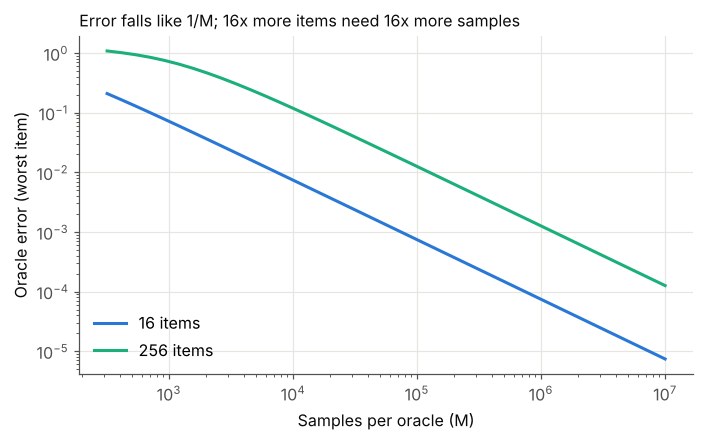

  16 items: ~7,896 samples per oracle for 1% error
 256 items: ~126,331 samples per oracle for 1% error


In [7]:
def expected_oracle(f, M):   # the oracle on average over many streams
    # Averaged QOS phase oracle (same formula as the reference qos.py).
    N = len(f)   # number of transactions
    # Averaged over fresh streams: each of the M draws misses x (chance
    # 1 - 1/N, no change) or hits x (chance 1/N, one nudge); M independent
    # draws multiply, hence the power M
    return (1 - 1/N + np.exp(1j * np.pi * N * f / M) / N) ** M

def oracle_error(f, M):   # how wrong the averaged oracle still is
    # Worst gap, over all transactions, between averaged and exact oracle
    return np.max(np.abs(expected_oracle(f, M) - np.exp(1j * np.pi * f)))

M_grid = np.unique(np.logspace(2.5, 7, 40).astype(int))   # ~300 to 10M samples
fig, ax = plt.subplots(figsize=(7.2, 4))   # one empty chart
for n_items, col in [(16, BLUE), (256, AQUA)]:            # 16 vs 256 transactions
    f_all = np.ones(n_items, dtype=int)                       # worst case: all "yes"
    # error against stream length, on log-log axes
    ax.loglog(M_grid, [oracle_error(f_all, m) for m in M_grid], color=col, label=f"{n_items} items")
# axis labels and title
ax.set_xlabel("Samples per oracle (M)"); ax.set_ylabel("Oracle error (worst item)")
# chart title, left-aligned
ax.set_title("Error falls like 1/M; 16x more items need 16x more samples",
             loc="left", color=INK, fontsize=10.5)   # title position, colour and size
ax.legend(loc="lower left"); plt.show()   # add the key, then display the chart

# Error ~ pi^2 N / (2M), so 1% error needs about 490 x N samples
for n_items in (16, 256):   # for 16 and for 256 transactions
    # print the samples needed for 1% error
    print(f"{n_items:>4} items: ~{np.pi**2 * n_items / (2 * 1e-2):,.0f} samples per oracle for 1% error")